# Detecting Fraudulent Ethereum Accounts Using Machine Learning
## 1. Problem Definition
Goal: classify an Ethereum account as fraudulent (FLAG = 1) or legitimate (FLAG = 0)
from its transaction behaviour. One row = one account.
Success measure: high Recall and PR-AUC on the fraud class (not accuracy).

In [1]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

RS = 42
sns.set_style("whitegrid")

print("Libraries loaded | pandas", pd.__version__)

Libraries loaded | pandas 3.0.6


In [2]:
for p in ["../data/transaction_dataset.csv", "data/transaction_dataset.csv"]:
    if os.path.exists(p):
        PATH = p
        break
else:
    raise FileNotFoundError("transaction_dataset.csv not found in the data folder")

df = pd.read_csv(PATH)
df.columns = df.columns.str.strip()
print(PATH, df.shape)

../data/transaction_dataset.csv (9841, 51)


In [3]:
df.head()

,Unnamed: 0,Index,Address,FLAG,Avg min between sent tnx,Avg min between received tnx,Time Diff between first and last (Mins),Sent tnx,Received Tnx,Number of Created Contracts,...,ERC20 min val sent,ERC20 max val sent,ERC20 avg val sent,ERC20 min val sent contract,ERC20 max val sent contract,ERC20 avg val sent contract,ERC20 uniq sent token name,ERC20 uniq rec token name,ERC20 most sent token type,ERC20_most_rec_token_type
0,0,1,0x00009277775ac7d0d59eaad8fee3d10ac6c805e8,0,844.26,1093.71,704785.63,721,89,0,...,0.000000,1.683100e+07,271779.920000,0.0,0.0,0.0,39.0,57.0,Cofoundit,Numeraire
1,1,2,0x0002b44ddb1476db43c868bd494422ee4c136fed,0,12709.07,2958.44,1218216.73,94,8,0,...,2.260809,2.260809e+00,2.260809,0.0,0.0,0.0,1.0,7.0,Livepeer Token,Livepeer Token
2,2,3,0x0002bda54cb772d040f779e88eb453cac0daa244,0,246194.54,2434.02,516729.30,2,10,0,...,0.000000,0.000000e+00,0.000000,0.0,0.0,0.0,0.0,8.0,NaN,XENON
3,3,4,0x00038e6ba2fd5c09aedb96697c8d7b8fa6632e5e,0,10219.60,15785.09,397555.90,25,9,0,...,100.000000,9.029231e+03,3804.076893,0.0,0.0,0.0,1.0,11.0,Raiden,XENON
4,4,5,0x00062d1dd1afb6fb02540ddad9cdebfe568e0d89,0,36.61,10707.77,382472.42,4598,20,1,...,0.000000,4.500000e+04,13726.659220,0.0,0.0,0.0,6.0,27.0,StatusNetwork,EOS


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9841 entries, 0 to 9840
Data columns (total 51 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   Unnamed: 0                                            9841 non-null   int64  
 1   Index                                                 9841 non-null   int64  
 2   Address                                               9841 non-null   str    
 3   FLAG                                                  9841 non-null   int64  
 4   Avg min between sent tnx                              9841 non-null   float64
 5   Avg min between received tnx                          9841 non-null   float64
 6   Time Diff between first and last (Mins)               9841 non-null   float64
 7   Sent tnx                                              9841 non-null   int64  
 8   Received Tnx                                          9841 non-null  

In [5]:
for i, col in enumerate(df.columns, start=1):
    print(i, col)

1 Unnamed: 0
2 Index
3 Address
4 FLAG
5 Avg min between sent tnx
6 Avg min between received tnx
7 Time Diff between first and last (Mins)
8 Sent tnx
9 Received Tnx
10 Number of Created Contracts
11 Unique Received From Addresses
12 Unique Sent To Addresses
13 min value received
14 max value received
15 avg val received
16 min val sent
17 max val sent
18 avg val sent
19 min value sent to contract
20 max val sent to contract
21 avg value sent to contract
22 total transactions (including tnx to create contract
23 total Ether sent
24 total ether received
25 total ether sent contracts
26 total ether balance
27 Total ERC20 tnxs
28 ERC20 total Ether received
29 ERC20 total ether sent
30 ERC20 total Ether sent contract
31 ERC20 uniq sent addr
32 ERC20 uniq rec addr
33 ERC20 uniq sent addr.1
34 ERC20 uniq rec contract addr
35 ERC20 avg time between sent tnx
36 ERC20 avg time between rec tnx
37 ERC20 avg time between rec 2 tnx
38 ERC20 avg time between contract tnx
39 ERC20 min val rec
40 ERC20 

In [6]:
print(df["FLAG"].value_counts())
print(df["FLAG"].value_counts(normalize=True).round(3))
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate addresses:", df["Address"].duplicated().sum())
print(df.isna().sum().sort_values(ascending=False).head(15))

FLAG
0    7662
1    2179
Name: count, dtype: int64
FLAG
0    0.779
1    0.221
Name: proportion, dtype: float64
Duplicate rows: 0
Duplicate addresses: 25
ERC20 most sent token type             2697
ERC20_most_rec_token_type               871
ERC20 avg val sent                      829
ERC20 total Ether received              829
ERC20 total ether sent                  829
ERC20 avg time between rec tnx          829
ERC20 avg time between rec 2 tnx        829
ERC20 max val rec                       829
ERC20 avg val rec                       829
ERC20 avg time between contract tnx     829
ERC20 avg time between sent tnx         829
ERC20 uniq rec addr                     829
ERC20 uniq sent addr.1                  829
ERC20 total Ether sent contract         829
ERC20 uniq sent addr                    829
dtype: int64


## 2. Data Understanding / Exploratory Data Analysis

FLAG
0    7662
1    2179
Name: count, dtype: int64
FLAG
0    0.779
1    0.221
Name: proportion, dtype: float64


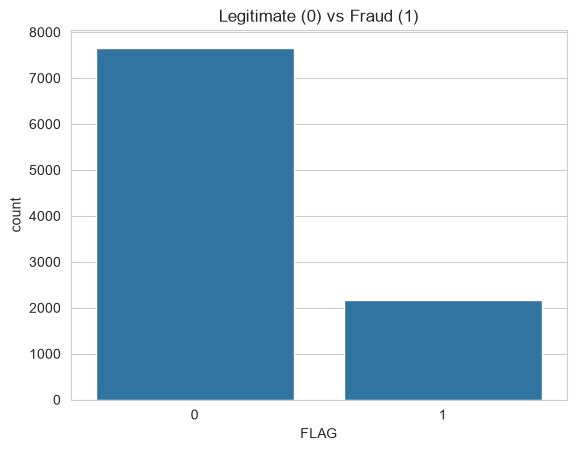

In [7]:
print(df["FLAG"].value_counts())
print(df["FLAG"].value_counts(normalize=True).round(3))

sns.countplot(x="FLAG", data=df)
plt.title("Legitimate (0) vs Fraud (1)")
plt.show()

In [8]:
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate addresses:", df["Address"].duplicated().sum())

print("\nMissing values (top 15):")
print(df.isna().sum().sort_values(ascending=False).head(15))

print("\nColumns with fewest unique values:")
print(df.nunique().sort_values().head(12))

Duplicate rows: 0
Duplicate addresses: 25

Missing values (top 15):
ERC20 most sent token type             2697
ERC20_most_rec_token_type               871
ERC20 avg val sent                      829
ERC20 total Ether received              829
ERC20 total ether sent                  829
ERC20 avg time between rec tnx          829
ERC20 avg time between rec 2 tnx        829
ERC20 max val rec                       829
ERC20 avg val rec                       829
ERC20 avg time between contract tnx     829
ERC20 avg time between sent tnx         829
ERC20 uniq rec addr                     829
ERC20 uniq sent addr.1                  829
ERC20 total Ether sent contract         829
ERC20 uniq sent addr                    829
dtype: int64

Columns with fewest unique values:
ERC20 avg time between rec 2 tnx       1
ERC20 max val sent contract            1
ERC20 min val sent contract            1
ERC20 avg val sent contract            1
ERC20 avg time between sent tnx        1
ERC20 avg time bet

In [9]:
skip = {"FLAG", "Index", "Unnamed: 0"}

num_all = [
    c for c in df.select_dtypes("number").columns
    if c not in skip
]

print("Number of numerical features:", len(num_all))
print(num_all)

Number of numerical features: 45
['Avg min between sent tnx', 'Avg min between received tnx', 'Time Diff between first and last (Mins)', 'Sent tnx', 'Received Tnx', 'Number of Created Contracts', 'Unique Received From Addresses', 'Unique Sent To Addresses', 'min value received', 'max value received', 'avg val received', 'min val sent', 'max val sent', 'avg val sent', 'min value sent to contract', 'max val sent to contract', 'avg value sent to contract', 'total transactions (including tnx to create contract', 'total Ether sent', 'total ether received', 'total ether sent contracts', 'total ether balance', 'Total ERC20 tnxs', 'ERC20 total Ether received', 'ERC20 total ether sent', 'ERC20 total Ether sent contract', 'ERC20 uniq sent addr', 'ERC20 uniq rec addr', 'ERC20 uniq sent addr.1', 'ERC20 uniq rec contract addr', 'ERC20 avg time between sent tnx', 'ERC20 avg time between rec tnx', 'ERC20 avg time between rec 2 tnx', 'ERC20 avg time between contract tnx', 'ERC20 min val rec', 'ERC20 m

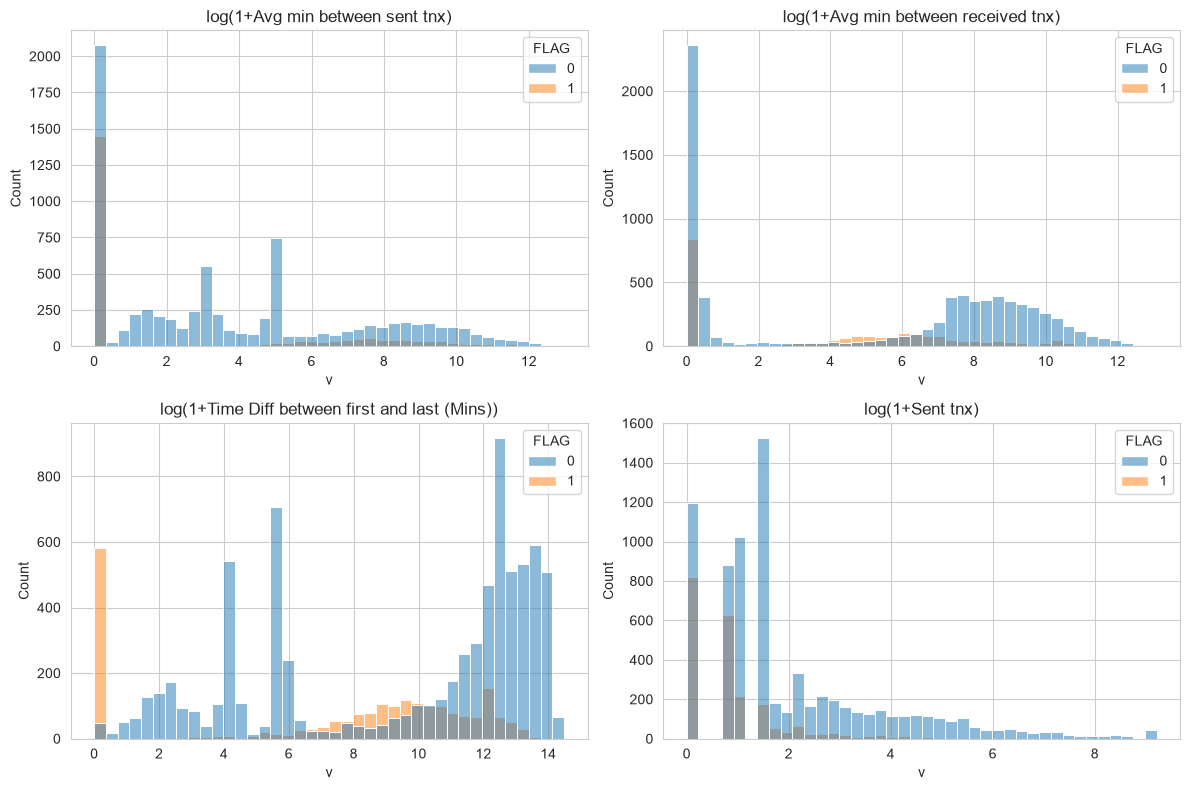

In [10]:
plot_cols = num_all[:4]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, c in zip(axes.ravel(), plot_cols):
    tmp = df.assign(v=np.log1p(df[c].clip(lower=0)))
    sns.histplot(data=tmp, x="v", hue="FLAG", bins=40, ax=ax)
    ax.set_title(f"log(1+{c})")

plt.tight_layout()
plt.show()

In [11]:
df.groupby("FLAG").median(numeric_only=True).T.head(20)

FLAG,0,1
Unnamed: 0,3830.500000,8751.000000
Index,1916.000000,1090.000000
Avg min between sent tnx,22.745000,0.000000
Avg min between received tnx,1402.135000,82.070000
Time Diff between first and last (Mins),116626.000000,7545.430000
Sent tnx,3.000000,1.000000
Received Tnx,5.000000,3.000000
Number of Created Contracts,0.000000,0.000000
Unique Received From Addresses,2.000000,3.000000
Unique Sent To Addresses,2.000000,1.000000


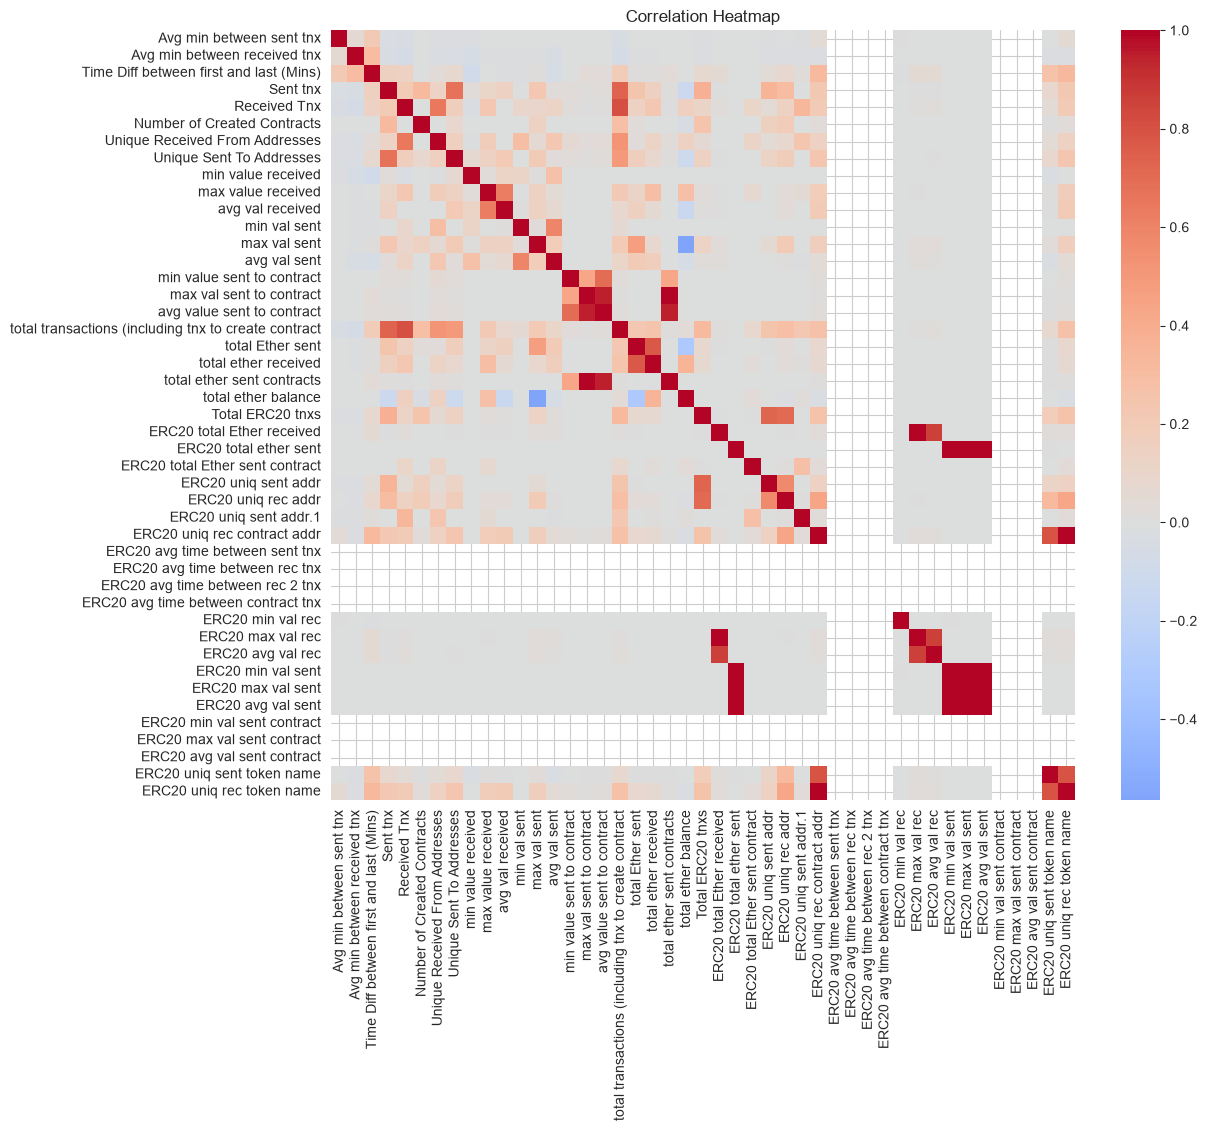

In [12]:
plt.figure(figsize=(12, 10))
sns.heatmap(df[num_all].corr(), cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

## 3. Data Cleaning / Preprocessing

In [13]:
df_raw = df.copy()

print("Raw data saved:", df_raw.shape)

Raw data saved: (9841, 51)


In [14]:
print("Total columns:", df_raw.shape[1])

print("Text columns:")
print(df_raw.select_dtypes(include="object").columns.tolist())

print("\nIdentifier columns present:")
print("Address:", "Address" in df_raw.columns)
print("Index:", "Index" in df_raw.columns)
print("Unnamed: 0:", "Unnamed: 0" in df_raw.columns)

Total columns: 51
Text columns:
['Address', 'ERC20 most sent token type', 'ERC20_most_rec_token_type']

Identifier columns present:
Address: True
Index: True
Unnamed: 0: True


In [15]:
dup = df_raw[df_raw["Address"].duplicated(keep=False)]

print("Rows involved in duplicate addresses:", len(dup))

conflict = dup.groupby("Address")["FLAG"].nunique()

print("Distinct duplicated addresses:", len(conflict))
print("Addresses with CONFLICTING labels:", int((conflict > 1).sum()))

Rows involved in duplicate addresses: 50
Distinct duplicated addresses: 25
Addresses with CONFLICTING labels: 0


In [16]:
id_cols = [c for c in ["Unnamed: 0", "Index", "Address"] if c in df_raw.columns]

feat_only = df_raw.drop(columns=id_cols)

same_all = feat_only.duplicated(keep="first")

print(
    "Rows identical to an earlier row (features AND label):",
    int(same_all.sum())
)

print(
    "Share of dataset:",
    round(same_all.mean() * 100, 2),
    "%"
)

print("\nLabels of repeated rows:")
print(feat_only[same_all]["FLAG"].value_counts())

Rows identical to an earlier row (features AND label): 546
Share of dataset: 5.55 %

Labels of repeated rows:
FLAG
1    523
0     23
Name: count, dtype: int64


In [17]:
# Start again from the original dataset
d = df_raw.copy()

# 1. Remove addresses that have conflicting labels
dup = d[d["Address"].duplicated(keep=False)]
conflict = dup.groupby("Address")["FLAG"].nunique()
bad_addr = conflict[conflict > 1].index

d = d[~d["Address"].isin(bad_addr)]

# 2. Keep only one row per Ethereum address
d = d.drop_duplicates(subset="Address", keep="first")

# 3. Remove identifier columns
id_cols = [c for c in ["Unnamed: 0", "Index", "Address"] if c in d.columns]
d = d.drop(columns=id_cols)

# 4. Remove constant columns
const = [c for c in d.columns if d[c].nunique() <= 1]
d = d.drop(columns=const)

# Final cleaned dataset
df = d.reset_index(drop=True)

print("Final cleaned shape:", df.shape)
print("\nFLAG counts:")
print(df["FLAG"].value_counts())

print("\nFraud share:")
print(round(df["FLAG"].mean() * 100, 2), "%")

print("\nConstant columns removed:", const)

Final cleaned shape: (9816, 41)

FLAG counts:
FLAG
0    7637
1    2179
Name: count, dtype: int64

Fraud share:
22.2 %

Constant columns removed: ['ERC20 avg time between sent tnx', 'ERC20 avg time between rec tnx', 'ERC20 avg time between rec 2 tnx', 'ERC20 avg time between contract tnx', 'ERC20 min val sent contract', 'ERC20 max val sent contract', 'ERC20 avg val sent contract']


In [18]:
miss = df.isna().sum()

miss = miss[miss > 0].sort_values(ascending=False)

print("Missing values:")
print(miss)

print()

print(
    "Share of accounts with at least one missing value:",
    round(df.isna().any(axis=1).mean() * 100, 1),
    "%"
)

Missing values:
ERC20 most sent token type         2689
ERC20_most_rec_token_type           871
ERC20 total Ether received          829
Total ERC20 tnxs                    829
ERC20 total ether sent              829
ERC20 total Ether sent contract     829
ERC20 uniq sent addr.1              829
ERC20 uniq rec contract addr        829
ERC20 uniq sent addr                829
ERC20 uniq rec addr                 829
ERC20 max val rec                   829
ERC20 min val rec                   829
ERC20 avg val rec                   829
ERC20 min val sent                  829
ERC20 avg val sent                  829
ERC20 max val sent                  829
ERC20 uniq rec token name           829
ERC20 uniq sent token name          829
dtype: int64

Share of accounts with at least one missing value: 27.6 %


## 4. Train-Test Split

In [19]:
print("Cleaned dataset shape:", df.shape)
print("Address column present:", "Address" in df.columns)
print(
    "Categorical columns:",
    df.select_dtypes(include="object").columns.tolist()
)

Cleaned dataset shape: (9816, 41)
Address column present: False
Categorical columns: ['ERC20 most sent token type', 'ERC20_most_rec_token_type']


In [20]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df.drop(columns="FLAG")
y = df["FLAG"]

# Stratified 80/20 split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)

print("\nFraud counts:")
print("Train:", int(y_train.sum()))
print("Test :", int(y_test.sum()))

print("\nFraud share:")
print("Overall:", round(y.mean() * 100, 2), "%")
print("Train  :", round(y_train.mean() * 100, 2), "%")
print("Test   :", round(y_test.mean() * 100, 2), "%")

print("\nRow overlap:",
      len(set(X_train.index) & set(X_test.index)) > 0)

Training shape: (7852, 40)
Testing shape: (1964, 40)

Fraud counts:
Train: 1743
Test : 436

Fraud share:
Overall: 22.2 %
Train  : 22.2 %
Test   : 22.2 %

Row overlap: False


### Train-Test Split Summary

- **Predictors:** 40 columns; **target:** `FLAG`.
- **Split method:** Stratified 80/20 train/test split with `random_state=42`.
- **Training set:** 7,852 accounts, including 1,743 fraudulent accounts.
- **Test set:** 1,964 accounts, including 436 fraudulent accounts.
- **Fraud proportion:** Approximately 22.2% in both sets.
- **Row overlap:** None.
- Data-dependent preprocessing is learned using the training data and then applied consistently to the test data.
- The test set is reserved for final evaluation, not model selection or threshold optimization.

## 5. Transformation and Feature Selection

The cleaned data is transformed into a model-ready numerical format. All data-dependent transformation decisions are learned from the training set only and then applied unchanged to the test set.

The transformation process includes:
1. Categorical encoding
2. Skewness reduction using signed log transformation
3. Correlation-based feature removal
4. Outlier capping
5. Final data verification

Missing numerical values and feature scaling will be handled later inside the model pipelines.

In [21]:
# Save untouched copies before transformation

X_train_base = X_train.copy()
X_test_base = X_test.copy()

print("Training base:", X_train_base.shape)
print("Testing base :", X_test_base.shape)

Training base: (7852, 40)
Testing base : (1964, 40)


### 5.1 Categorical Feature Inspection

The dataset contains ERC20 token-type columns with text values. These columns cannot be used directly by the machine-learning models, so they will be converted into numerical features.

In [22]:
# Identify text/categorical columns

cat_cols = X_train_base.select_dtypes(include="object").columns.tolist()

print("Text columns:", cat_cols)

for c in cat_cols:
    print("\n", c)
    print("Unique values in train:", X_train_base[c].nunique())
    print("Missing values in train:", int(X_train_base[c].isna().sum()))
    print(X_train_base[c].value_counts().head(8))

Text columns: ['ERC20 most sent token type', 'ERC20_most_rec_token_type']

 ERC20 most sent token type
Unique values in train: 278
Missing values in train: 2171
ERC20 most sent token type
0                                3503
                                  949
OmiseGO                           115
blockwell.ai KYC Casper Token     109
EOS                               105
Golem                             103
StatusNetwork                      47
BAT                                33
Name: count, dtype: int64

 ERC20_most_rec_token_type
Unique values in train: 395
Missing values in train: 708
ERC20_most_rec_token_type
0                        3503
OmiseGO                   692
Blockwell say NOTSAFU     616
DATAcoin                  291
Livepeer Token            156
EOS                       130
XENON                     119
Golem                     100
Name: count, dtype: int64


### 5.2 Categorical Encoding

The categorical variables are transformed as follows:

- Missing values are labelled as `Unknown`.
- The 10 most frequent categories in the training set are retained.
- Less frequent categories are grouped into `Other`.
- The resulting categories are converted into binary features using one-hot encoding.

The category selection is learned from the training set only.

In [23]:
TOP_N = 10

# Fill missing categorical values
def fill_unknown(data):
    data = data.copy()

    for c in cat_cols:
        data[c] = (
            data[c]
            .fillna("Unknown")
            .astype(str)
            .str.strip()
        )

    return data


# Learn the most frequent categories from TRAINING data only
tmp = fill_unknown(X_train_base)

top = {
    c: tmp[c].value_counts().nlargest(TOP_N).index
    for c in cat_cols
}


# Group rare categories
def group_rare(data):
    data = fill_unknown(data)

    for c in cat_cols:
        data[c] = data[c].where(
            data[c].isin(top[c]),
            "Other"
        )

    return data


# One-hot encode
X_tr_enc = pd.get_dummies(
    group_rare(X_train_base),
    columns=cat_cols,
    dtype=int
)

X_te_enc = pd.get_dummies(
    group_rare(X_test_base),
    columns=cat_cols,
    dtype=int
)

# Make test columns exactly match training columns
X_te_enc = X_te_enc.reindex(
    columns=X_tr_enc.columns,
    fill_value=0
)

print("Train:", X_tr_enc.shape)
print("Test :", X_te_enc.shape)

print(
    "New 0/1 columns added:",
    X_tr_enc.shape[1] - X_train_base.shape[1]
)

print(
    "Same columns in train and test?",
    list(X_tr_enc.columns) == list(X_te_enc.columns)
)

Train: (7852, 60)
Test : (1964, 60)
New 0/1 columns added: 20
Same columns in train and test? True


### 5.3 Skewness Transformation

Many transaction-related numerical features have highly skewed distributions because a small number of accounts can have extremely large transaction values.

A signed logarithmic transformation is applied to continuous features with absolute skewness greater than 2. Binary one-hot encoded features are excluded.

The transformation is:

`sign(x) × log(1 + |x|)`

This also allows features containing negative values to be transformed safely.

In [24]:
def signed_log(x):
    return np.sign(x) * np.log1p(np.abs(x))


# Only continuous features
cand = [
    c for c in X_tr_enc.columns
    if X_tr_enc[c].nunique() > 2
]

# Calculate skewness using training data only
skew_before = X_tr_enc[cand].skew()

# Select strongly skewed features
skewed = [
    c for c in cand
    if abs(skew_before[c]) > 2
]

# Create transformed copies
X_tr_log = X_tr_enc.copy()
X_te_log = X_te_enc.copy()

# Apply the same transformation to train and test
X_tr_log[skewed] = signed_log(X_tr_log[skewed])
X_te_log[skewed] = signed_log(X_te_log[skewed])

# Check improvement
skew_after = X_tr_log[skewed].skew()

print(
    "Continuous columns checked:",
    len(cand)
)

print(
    "Log-transformed columns:",
    len(skewed)
)

print(
    "Average |skew| before:",
    round(skew_before[skewed].abs().mean(), 2)
)

print(
    "Average |skew| after:",
    round(skew_after.abs().mean(), 2)
)

Continuous columns checked: 38
Log-transformed columns: 37
Average |skew| before: 46.66
Average |skew| after: 10.46


### 5.4 Correlation-Based Feature Selection

Highly correlated features provide largely redundant information and can create unnecessary multicollinearity.

Features with an absolute correlation greater than 0.95 are identified using the training data. The selected redundant features are removed from both the training and test sets.

In [25]:
# Calculate absolute correlations using training data only
corr = X_tr_log.corr().abs()

# Keep only the upper triangle
upper = corr.where(
    np.triu(
        np.ones(corr.shape),
        k=1
    ).astype(bool)
)

# Identify highly correlated features
drop_corr = [
    c for c in upper.columns
    if (upper[c] > 0.95).any()
]

# Remove the same features from train and test
X_tr_corr = X_tr_log.drop(columns=drop_corr)
X_te_corr = X_te_log.drop(columns=drop_corr)

print(
    "Dropped",
    len(drop_corr),
    "highly correlated columns:"
)

print(drop_corr)

print(
    "\nShape after correlation filtering:",
    X_tr_corr.shape
)

Dropped 10 highly correlated columns:
['avg value sent to contract', 'total ether sent contracts', 'ERC20 uniq rec addr', 'ERC20 uniq rec contract addr', 'ERC20 max val rec', 'ERC20 avg val rec', 'ERC20 max val sent', 'ERC20 avg val sent', 'ERC20 uniq rec token name', 'ERC20_most_rec_token_type_0']

Shape after correlation filtering: (7852, 50)


### 5.5 Outlier Capping

Extreme values are capped using the 1st and 99th percentiles calculated from the training data.

Only continuous features are considered. Binary features are excluded, and features for which the lower and upper percentile values are identical are skipped because capping them would remove their remaining variation.

The same training-derived limits are applied to the test set.

In [26]:
# Identify continuous features
cont = [
    c for c in X_tr_corr.columns
    if X_tr_corr[c].nunique() > 2
]

# Learn percentile limits from TRAINING data only
lo = X_tr_corr[cont].quantile(0.01)
hi = X_tr_corr[cont].quantile(0.99)

# Only cap columns where capping preserves variation
cap_cols = [
    c for c in cont
    if hi[c] > lo[c]
]

skipped = [
    c for c in cont
    if hi[c] <= lo[c]
]

# Create copies
X_tr_cap = X_tr_corr.copy()
X_te_cap = X_te_corr.copy()

# Apply training-derived caps
X_tr_cap[cap_cols] = X_tr_corr[cap_cols].clip(
    lower=lo[cap_cols],
    upper=hi[cap_cols],
    axis=1
)

X_te_cap[cap_cols] = X_te_corr[cap_cols].clip(
    lower=lo[cap_cols],
    upper=hi[cap_cols],
    axis=1
)

print(
    "Continuous columns:",
    len(cont),
    "| Capped:",
    len(cap_cols),
    "| Skipped:",
    len(skipped)
)

print(
    "\nSkipped columns:",
    skipped
)

# Check how much distinct-value information was retained
loss = (
    X_tr_cap[cap_cols].nunique()
    / X_tr_corr[cap_cols].nunique()
).sort_values()

print("\nColumns that lost the most distinct values:")
print(loss.head(8).round(3))

Continuous columns: 29 | Capped: 25 | Skipped: 4

Skipped columns: ['min value sent to contract', 'max val sent to contract', 'ERC20 total Ether sent contract', 'ERC20 uniq sent addr.1']

Columns that lost the most distinct values:
Number of Created Contracts       0.118
ERC20 uniq sent addr              0.436
ERC20 uniq sent token name        0.493
Unique Received From Addresses    0.649
Unique Sent To Addresses          0.665
Total ERC20 tnxs                  0.788
ERC20 min val sent                0.845
Sent tnx                          0.877
dtype: float64


### 5.6 Transformation Verification

The transformed training and test datasets are checked to ensure that:

- both datasets contain the same features in the same order,
- no categorical/text columns remain,
- no infinite values were created,
- no constant columns remain,
- remaining numerical missing values are identified for later pipeline-based imputation.

In [27]:
print("Train:", X_tr_cap.shape)
print("Test :", X_te_cap.shape)

print(
    "Same columns, same order?",
    list(X_tr_cap.columns) == list(X_te_cap.columns)
)

print(
    "Text columns left:",
    X_tr_cap.select_dtypes(include="object").columns.tolist()
)

print(
    "Infinite values:",
    int(np.isinf(X_tr_cap).sum().sum()),
    int(np.isinf(X_te_cap).sum().sum())
)

print(
    "Constant columns now:",
    [
        c for c in X_tr_cap.columns
        if X_tr_cap[c].nunique() <= 1
    ]
)

print("\nColumns with missing values in training:")

m = X_tr_cap.isna().sum()
print(m[m > 0])

Train: (7852, 50)
Test : (1964, 50)
Same columns, same order? True
Text columns left: []
Infinite values: 0 0
Constant columns now: []

Columns with missing values in training:
Total ERC20 tnxs                   673
ERC20 total Ether received         673
ERC20 total ether sent             673
ERC20 total Ether sent contract    673
ERC20 uniq sent addr               673
ERC20 uniq sent addr.1             673
ERC20 min val rec                  673
ERC20 min val sent                 673
ERC20 uniq sent token name         673
dtype: int64


In [28]:
# Final transformed datasets for modelling

X_train = X_tr_cap.copy()
X_test = X_te_cap.copy()

print("Final model inputs:")
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)

print("\ny_train:", y_train.shape)
print("y_test :", y_test.shape)

print(
    "\nSame columns?",
    list(X_train.columns) == list(X_test.columns)
)

Final model inputs:
X_train: (7852, 50)
X_test : (1964, 50)

y_train: (7852,)
y_test : (1964,)

Same columns? True


### Transformation Summary

- **Categorical encoding:** The two ERC20 token-type columns were handled by replacing missing values with `Unknown`, retaining the 10 most frequent categories learned from the training set, grouping remaining categories as `Other`, and applying one-hot encoding. This added 20 binary features.
- **Log transformation:** 37 of 38 continuous features were strongly skewed (`|skew| > 2`) and transformed using a signed logarithm. Average absolute skewness decreased from **46.66 to 10.46**.
- **Correlation filtering:** 10 features with absolute correlation greater than **0.95** were removed.
- **Outlier capping:** 25 continuous features were capped at the 1st and 99th percentiles calculated from the training data. 4 features were skipped because capping would remove their variation.
- **Final feature count:** **50**.
- The final training set contains **7,852 accounts** and the test set contains **1,964 accounts**.
- Training and test sets contain the same 50 features in the same order.
- No text columns, infinite values, or constant columns remain.
- Missing values remain in 9 ERC20-related numerical columns and will be handled inside the model pipelines.
- All transformation decisions were learned from the training data and applied unchanged to the test data.

### 6. Baseline and Model Development

### 6.1 Final Dataset Verification

Before model development, the final training and testing datasets are verified to ensure that the corrected dataset and transformed features are being used.

In [29]:
# Final dataset verification

print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)

print("\nClass distribution:")
print("Training:")
print(y_train.value_counts())

print("\nTesting:")
print(y_test.value_counts())

print("\nFraud share:")
print("Train:", round(y_train.mean() * 100, 2), "%")
print("Test :", round(y_test.mean() * 100, 2), "%")

print("\nSame feature columns:",
      list(X_train.columns) == list(X_test.columns))

X_train: (7852, 50)
X_test : (1964, 50)
y_train: (7852,)
y_test : (1964,)

Class distribution:
Training:
FLAG
0    6109
1    1743
Name: count, dtype: int64

Testing:
FLAG
0    1528
1     436
Name: count, dtype: int64

Fraud share:
Train: 22.2 %
Test : 22.2 %

Same feature columns: True


### 6.2 Safety Checks Before Modeling

Before training the models, the feature names and data are checked for compatibility with the machine-learning libraries. Missing values are also identified because they will be handled inside the model pipelines.

In [30]:
import re
import time

# Make feature names safe for XGBoost and other model libraries
def clean_name(c):
    return re.sub(
        r"[^0-9a-zA-Z_]+",
        "_",
        str(c)
    ).strip("_")


# Clean feature names
new_cols = [clean_name(c) for c in X_train.columns]

# Check that cleaning did not create duplicate names
unique_ok = len(set(new_cols)) == len(new_cols)

print("Names unique after cleaning?", unique_ok)

if not unique_ok:
    print("Duplicate names:")
    print(
        pd.Series(new_cols)
        [pd.Series(new_cols).duplicated(keep=False)]
        .tolist()
    )
else:
    X_train.columns = new_cols
    X_test.columns = new_cols


# Check completely empty columns
empty_cols = X_train.columns[
    X_train.isna().all()
].tolist()

print("\nCompletely empty columns in train:")
print(empty_cols)


# Check train/test feature consistency
print(
    "\nSame columns in train and test?",
    list(X_train.columns) == list(X_test.columns)
)


# Check class balance
print(
    "\nFraud share in training:",
    round(y_train.mean(), 3)
)


# Check missing values
missing_cols = X_train.columns[
    X_train.isna().any()
].tolist()

print("\nColumns with missing values:")
print(missing_cols)


# Check infinite values
print(
    "\nInfinite values in train:",
    int(np.isinf(X_train).sum().sum())
)

print(
    "Infinite values in test:",
    int(np.isinf(X_test).sum().sum())
)

Names unique after cleaning? True

Completely empty columns in train:
[]

Same columns in train and test? True

Fraud share in training: 0.222

Columns with missing values:
['Total_ERC20_tnxs', 'ERC20_total_Ether_received', 'ERC20_total_ether_sent', 'ERC20_total_Ether_sent_contract', 'ERC20_uniq_sent_addr', 'ERC20_uniq_sent_addr_1', 'ERC20_min_val_rec', 'ERC20_min_val_sent', 'ERC20_uniq_sent_token_name']

Infinite values in train: 0
Infinite values in test: 0


### 6.3 Baseline Model

A Dummy Classifier is used as a baseline. It predicts the majority class for every account and therefore does not learn transaction behaviour.

The baseline is evaluated using the same 5-fold stratified cross-validation framework that will be used for the machine-learning models.

Because fraudulent accounts represent 22.2% of the training data, a majority-class classifier is expected to achieve approximately 77.8% accuracy while detecting no fraudulent accounts.

In [31]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Metrics
scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc",
    "average_precision"
]


# Common CV function for baseline and later models
def run_cv(model):
    t0 = time.time()

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    mean = {
        metric.replace("test_", ""): scores[metric].mean()
        for metric in scores
        if metric.startswith("test_")
    }

    std = {
        metric.replace("test_", ""): scores[metric].std()
        for metric in scores
        if metric.startswith("test_")
    }

    elapsed = round(time.time() - t0, 1)

    return mean, std, elapsed


# Majority-class baseline
baseline = DummyClassifier(
    strategy="most_frequent"
)

base_mean, base_std, base_time = run_cv(baseline)

print("Baseline mean scores:")
print(pd.Series(base_mean).round(3))

print("\nBaseline standard deviation:")
print(pd.Series(base_std).round(3))

print("\nTime:", base_time, "seconds")

Baseline mean scores:
accuracy             0.778
precision            0.000
recall               0.000
f1                   0.000
roc_auc              0.500
average_precision    0.222
dtype: float64

Baseline standard deviation:
accuracy             0.0
precision            0.0
recall               0.0
f1                   0.0
roc_auc              0.0
average_precision    0.0
dtype: float64

Time: 2.9 seconds


### Baseline Interpretation

The majority-class baseline predicts every account as legitimate. Although it achieves relatively high accuracy because legitimate accounts form the majority class, it detects none of the fraudulent accounts.

Therefore, accuracy alone is not an appropriate metric for this problem. PR-AUC, recall, precision and F1-score are more informative for evaluating fraud detection performance.

### 6.4 Define the Machine-Learning Models

Four classification models are compared:

1. Logistic Regression
2. Decision Tree
3. Random Forest
4. XGBoost

Missing numerical values are imputed using the median within each training fold. SMOTE is applied inside the pipelines for Logistic Regression, Decision Tree and Random Forest so that synthetic samples are generated only from the training portion of each cross-validation fold.

XGBoost uses `scale_pos_weight` instead of SMOTE to handle class imbalance.

In [32]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier


# Reproducibility
RS = 42


# Calculate legitimate-to-fraud ratio
imb_ratio = (
    (y_train == 0).sum()
    / (y_train == 1).sum()
)

print(
    "Legitimate-to-fraud ratio:",
    round(imb_ratio, 2)
)


# Define models
models = {

    "Logistic Regression": Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        ),
        (
            "smote",
            SMOTE(random_state=RS)
        ),
        (
            "model",
            LogisticRegression(
                max_iter=3000,
                random_state=RS
            )
        )
    ]),

    "Decision Tree": Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "smote",
            SMOTE(random_state=RS)
        ),
        (
            "model",
            DecisionTreeClassifier(
                random_state=RS
            )
        )
    ]),

    "Random Forest": Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "smote",
            SMOTE(random_state=RS)
        ),
        (
            "model",
            RandomForestClassifier(
                n_estimators=300,
                random_state=RS,
                n_jobs=1
            )
        )
    ]),

    "XGBoost": Pipeline([
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "model",
            XGBClassifier(
                scale_pos_weight=imb_ratio,
                eval_metric="logloss",
                random_state=RS,
                n_jobs=1
            )
        )
    ])
}


print("\nModels defined:")
for name in models:
    print("-", name)

Legitimate-to-fraud ratio: 3.5

Models defined:
- Logistic Regression
- Decision Tree
- Random Forest
- XGBoost


### 6.5 Five-Fold Cross-Validation

The four machine-learning models are evaluated using 5-fold stratified cross-validation on the training data.

Stratification preserves the fraud/legitimate class ratio in each fold. Imputation, scaling and SMOTE are performed inside the model pipelines, so these operations are refitted independently within each training fold.

The test set is not used during model comparison.

In [33]:
# Store cross-validation results

results_mean = {}
results_std = {}
times = {}

# Add baseline to the comparison
results_mean["Baseline (majority class)"] = base_mean
results_std["Baseline (majority class)"] = base_std
times["Baseline (majority class)"] = base_time


# Run 5-fold CV for each model
for name, model in models.items():

    print(f"Running {name}...", end=" ")

    mean_scores, std_scores, elapsed = run_cv(model)

    results_mean[name] = mean_scores
    results_std[name] = std_scores
    times[name] = elapsed

    print(f"done in {elapsed} seconds")


# Create result tables
cv_table = pd.DataFrame(results_mean).T.round(3)

cv_std = pd.DataFrame(results_std).T.round(3)

cv_table["fit_time_s"] = pd.Series(times)


# Sort models by PR-AUC
cv_table_sorted = cv_table.sort_values(
    "average_precision",
    ascending=False
)

print("\nCross-validation results:")
display(cv_table_sorted)

Running Logistic Regression... done in 2.7 seconds
Running Decision Tree... done in 2.2 seconds
Running Random Forest... done in 4.0 seconds
Running XGBoost... done in 0.6 seconds

Cross-validation results:


,accuracy,precision,recall,f1,roc_auc,average_precision,fit_time_s
Random Forest,0.993,0.996,0.972,0.984,0.999,0.999,4.0
XGBoost,0.995,0.995,0.983,0.989,0.999,0.998,0.6
Logistic Regression,0.989,0.966,0.983,0.974,0.998,0.995,2.7
Decision Tree,0.988,0.970,0.974,0.972,0.983,0.951,2.2
Baseline (majority class),0.778,0.000,0.000,0.000,0.500,0.222,2.9


In [34]:
print("Cross-validation standard deviations:")

display(
    cv_std[
        ["recall", "f1", "average_precision"]
    ].round(3)
)

Cross-validation standard deviations:


,recall,f1,average_precision
Baseline (majority class),0.000,0.000,0.000
Logistic Regression,0.006,0.007,0.002
Decision Tree,0.005,0.004,0.008
Random Forest,0.007,0.004,0.001
XGBoost,0.008,0.006,0.002


### 6.6 Cross-Validation Leakage Diagnostics

Before selecting the best models, repeated feature patterns across cross-validation folds are examined. This helps identify whether identical feature vectors appear in both training and validation subsets.

In [35]:
# Check identical feature patterns across CV folds

fold_results = []

for fold, (train_idx, val_idx) in enumerate(
    cv.split(X_train, y_train), start=1
):
    X_fold_train = X_train.iloc[train_idx]
    X_fold_val = X_train.iloc[val_idx]

    # Compare feature patterns, treating NaNs consistently
    train_patterns = pd.util.hash_pandas_object(
        X_fold_train, index=False
    )

    val_patterns = pd.util.hash_pandas_object(
        X_fold_val, index=False
    )

    overlap = val_patterns.isin(set(train_patterns))

    fold_results.append({
        "Fold": fold,
        "Validation rows": len(X_fold_val),
        "Repeated patterns": int(overlap.sum()),
        "Overlap %": round(overlap.mean() * 100, 2)
    })

overlap_df = pd.DataFrame(fold_results)

display(overlap_df)

print(
    "\nAverage overlap:",
    round(overlap_df["Overlap %"].mean(), 2),
    "%"
)

,Fold,Validation rows,Repeated patterns,Overlap %
0,1,1571,92,5.86
1,2,1571,88,5.60
2,3,1570,70,4.46
3,4,1570,93,5.92
4,5,1570,90,5.73



Average overlap: 5.51 %


### 6.7 Repeated Feature Pattern and Target Consistency Check

Identical feature patterns are examined to determine whether they consistently correspond to the same target class. This helps assess whether the high cross-validation performance is partly influenced by repeated behavioural patterns in the dataset.

In [36]:
# Check whether repeated feature patterns have consistent labels

# Use the original training data before transformation
pattern_data = X_train_base.copy()
pattern_data["FLAG"] = y_train.values

feature_cols = X_train_base.columns.tolist()

pattern_stats = (
    pattern_data
    .groupby(feature_cols, dropna=False)["FLAG"]
    .agg(
        count="size",
        unique_labels="nunique",
        fraud_count="sum"
    )
    .reset_index()
)

# Patterns occurring more than once
repeated_patterns = pattern_stats[
    pattern_stats["count"] > 1
].copy()

# Patterns appearing with both labels
mixed_patterns = repeated_patterns[
    repeated_patterns["unique_labels"] > 1
].copy()

print("Total training accounts:", len(pattern_data))
print(
    "Unique feature patterns:",
    len(pattern_stats)
)

print(
    "Repeated feature patterns:",
    len(repeated_patterns)
)

print(
    "Repeated patterns appearing with BOTH labels:",
    len(mixed_patterns)
)

print(
    "\nAccounts belonging to repeated patterns:",
    int(repeated_patterns["count"].sum())
)

print(
    "Accounts belonging to mixed-label patterns:",
    int(mixed_patterns["count"].sum())
)

Total training accounts: 7852
Unique feature patterns: 7428
Repeated feature patterns: 9
Repeated patterns appearing with BOTH labels: 0

Accounts belonging to repeated patterns: 433
Accounts belonging to mixed-label patterns: 0


In [37]:
# Show the largest repeated feature patterns

print("Largest repeated feature patterns:")

display(
    repeated_patterns
    .sort_values("count", ascending=False)
    [["count", "unique_labels", "fraud_count"]]
    .head(15)
)

Largest repeated feature patterns:


,count,unique_labels,fraud_count
11,216,1,216
1,102,1,102
0,96,1,96
12,6,1,6
2,4,1,4
32,3,1,0
4,2,1,2
22,2,1,0
5032,2,1,0


### 6.8 Feature-Target Leakage Diagnostic

Individual features are examined for unusually strong relationships with the target variable. This check helps identify whether any feature may act as a direct proxy for the fraud label.

The target variable itself is not included among the predictors.

In [38]:
from sklearn.metrics import roc_auc_score

# Use the original training features before model transformations
X_check = X_train_base.copy()
y_check = y_train.copy()

feature_scores = []

for col in X_check.columns:

    # Only evaluate numerical features
    if not pd.api.types.is_numeric_dtype(X_check[col]):
        continue

    x = X_check[col]

    # Skip completely missing or constant features
    if x.isna().all() or x.nunique(dropna=True) <= 1:
        continue

    # Median fill ONLY for this diagnostic
    x_filled = x.fillna(x.median())

    try:
        auc = roc_auc_score(y_check, x_filled)

        # AUC below 0.5 can be reversed
        auc_strength = max(auc, 1 - auc)

        feature_scores.append({
            "feature": col,
            "auc_strength": auc_strength,
            "raw_auc": auc
        })

    except Exception:
        pass


feature_auc = (
    pd.DataFrame(feature_scores)
    .sort_values("auc_strength", ascending=False)
    .reset_index(drop=True)
)

display(feature_auc.head(15))

,feature,auc_strength,raw_auc
0,total ether received,0.814613,0.185387
1,avg val received,0.791060,0.208940
2,max value received,0.779835,0.220165
3,total Ether sent,0.731493,0.268507
4,Sent tnx,0.723315,0.276685
5,min value received,0.705660,0.294340
6,max val sent,0.698898,0.301102
7,Time Diff between first and last (Mins),0.685191,0.314809
8,total transactions (including tnx to create co...,0.683663,0.316337
9,total ether balance,0.676369,0.323631


In [39]:
print(
    "Features with univariate AUC >= 0.95:",
    int((feature_auc["auc_strength"] >= 0.95).sum())
)

print(
    "\nTop feature:",
    feature_auc.iloc[0]["feature"],
    "| AUC:",
    round(feature_auc.iloc[0]["auc_strength"], 3)
)

Features with univariate AUC >= 0.95: 0

Top feature: total ether received | AUC: 0.815


## 7. Hyperparameter Tuning

The two best-performing models from cross-validation are selected for hyperparameter tuning based primarily on PR-AUC.

The selected models are:

1. Random Forest
2. XGBoost

Hyperparameter tuning is performed using the training set only with 5-fold stratified cross-validation. Average Precision (PR-AUC) is used as the primary scoring metric because the objective is fraudulent-account detection under class imbalance.

The test set remains completely untouched until the final evaluation.

### 7.1 Select Models for Tuning

In [40]:
# Rank the real models by cross-validated PR-AUC

ranking = (
    cv_table
    .drop(index="Baseline (majority class)")
    .sort_values(
        "average_precision",
        ascending=False
    )
)

print("Model ranking by PR-AUC:")
display(
    ranking[
        [
            "precision",
            "recall",
            "f1",
            "roc_auc",
            "average_precision"
        ]
    ]
)

# Select the top two models
top2 = ranking.index[:2].tolist()

print("\nModels selected for hyperparameter tuning:")
for i, name in enumerate(top2, start=1):
    print(f"{i}. {name}")

Model ranking by PR-AUC:


,precision,recall,f1,roc_auc,average_precision
Random Forest,0.996,0.972,0.984,0.999,0.999
XGBoost,0.995,0.983,0.989,0.999,0.998
Logistic Regression,0.966,0.983,0.974,0.998,0.995
Decision Tree,0.970,0.974,0.972,0.983,0.951



Models selected for hyperparameter tuning:
1. Random Forest
2. XGBoost


### 7.2 Hyperparameter Search Setup

Randomized search is used instead of testing every possible parameter combination. This provides a practical balance between search coverage and computation time.

Average Precision (PR-AUC) is used as the optimization metric.

In [41]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint, uniform, loguniform

print("Hyperparameter tuning setup ready.")

Hyperparameter tuning setup ready.


### 7.3 Random Forest Hyperparameter Search

The Random Forest search varies the number of trees, tree depth, minimum samples required for splitting and leaf nodes, and the number of features considered at each split.

SMOTE and median imputation remain inside the pipeline.

In [42]:
rf_pipeline = models["Random Forest"]

rf_params = {
    "model__n_estimators": randint(200, 501),
    "model__max_depth": [None, 10, 15, 20, 25, 30],
    "model__min_samples_split": randint(2, 11),
    "model__min_samples_leaf": randint(1, 6),
    "model__max_features": ["sqrt", "log2", 0.5, 0.75]
}

print("Random Forest search space created.")

Random Forest search space created.


In [43]:
rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_params,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=RS,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

print("Starting Random Forest tuning...")

rf_search.fit(X_train, y_train)

print("\nRandom Forest tuning completed.")
print("Best PR-AUC:", round(rf_search.best_score_, 4))
print("Best parameters:")

for param, value in rf_search.best_params_.items():
    print(f"{param}: {value}")

Starting Random Forest tuning...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

Random Forest tuning completed.
Best PR-AUC: 0.9986
Best parameters:
model__max_depth: 25
model__max_features: sqrt
model__min_samples_leaf: 1
model__min_samples_split: 8
model__n_estimators: 208


### 7.4 XGBoost Hyperparameter Search

XGBoost hyperparameters are tuned while retaining the training-set class imbalance adjustment through `scale_pos_weight`.

Median imputation remains inside the pipeline.

In [44]:
xgb_pipeline = models["XGBoost"]

xgb_params = {
    "model__n_estimators": randint(100, 501),
    "model__max_depth": randint(3, 9),
    "model__learning_rate": loguniform(0.01, 0.2),
    "model__min_child_weight": randint(1, 8),
    "model__subsample": uniform(0.7, 0.3),
    "model__colsample_bytree": uniform(0.7, 0.3),
    "model__gamma": uniform(0, 2),
    "model__reg_alpha": loguniform(1e-4, 1),
    "model__reg_lambda": loguniform(0.1, 10)
}

print("XGBoost search space created.")

XGBoost search space created.


In [45]:
xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_params,
    n_iter=20,
    scoring="average_precision",
    cv=cv,
    random_state=RS,
    n_jobs=-1,
    verbose=1,
    return_train_score=False
)

print("Starting XGBoost tuning...")

xgb_search.fit(X_train, y_train)

print("\nXGBoost tuning completed.")
print("Best PR-AUC:", round(xgb_search.best_score_, 4))
print("Best parameters:")

for param, value in xgb_search.best_params_.items():
    print(f"{param}: {value}")

Starting XGBoost tuning...
Fitting 5 folds for each of 20 candidates, totalling 100 fits

XGBoost tuning completed.
Best PR-AUC: 0.9987
Best parameters:
model__colsample_bytree: 0.9084354799119113
model__gamma: 1.7609356780305154
model__learning_rate: 0.06490876477881215
model__max_depth: 8
model__min_child_weight: 1
model__n_estimators: 233
model__reg_alpha: 0.0067009793859898305
model__reg_lambda: 0.2734518553865505
model__subsample: 0.8249529843611099


### 7.5 Tuned Model Comparison

In [46]:
tuned_results = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],
    "Best CV PR-AUC": [
        rf_search.best_score_,
        xgb_search.best_score_
    ]
})

tuned_results["Best CV PR-AUC"] = (
    tuned_results["Best CV PR-AUC"].round(4)
)

display(
    tuned_results.sort_values(
        "Best CV PR-AUC",
        ascending=False
    ).reset_index(drop=True)
)

,Model,Best CV PR-AUC
0,XGBoost,0.9987
1,Random Forest,0.9986


### 7.6 Hyperparameter Tuning Summary

Randomized hyperparameter search was performed for the Random Forest and XGBoost models using 5-fold stratified cross-validation and Average Precision (PR-AUC) as the optimization metric.

The tuned XGBoost model achieved the highest cross-validated PR-AUC of **0.9987**, while the tuned Random Forest achieved **0.9986**.

The tuning results show that both models were already performing very strongly before optimization. Therefore, the small difference between the tuned models should be interpreted together with recall, precision, F1-score and final test performance rather than PR-AUC alone.

The test set was not used during hyperparameter tuning.

## 8. Threshold Selection

The default classification threshold of 0.50 is not assumed to be optimal for fraud detection.

Out-of-fold probability predictions are generated from the training data using 5-fold stratified cross-validation. These predictions are used to evaluate different probability thresholds.

The threshold is selected using training data only. The test set remains completely untouched and will be used only for the final evaluation.

### 8.1 Generate Out-of-Fold Probabilities

Out-of-fold (OOF) probabilities are generated for the tuned Random Forest and XGBoost models.

For each training account, its fraud probability is produced by a model trained without that account. This provides an unbiased training-based prediction set for threshold selection.

In [47]:
from sklearn.model_selection import cross_val_predict

# Tuned models
rf_best = rf_search.best_estimator_
xgb_best = xgb_search.best_estimator_

print("Generating out-of-fold probabilities...")

# Random Forest OOF probabilities
rf_oof_prob = cross_val_predict(
    rf_best,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("Random Forest OOF predictions completed.")

# XGBoost OOF probabilities
xgb_oof_prob = cross_val_predict(
    xgb_best,
    X_train,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

print("XGBoost OOF predictions completed.")

print("\nPrediction counts:")
print("Random Forest:", len(rf_oof_prob))
print("XGBoost      :", len(xgb_oof_prob))
print("Training     :", len(y_train))

Generating out-of-fold probabilities...
Random Forest OOF predictions completed.
XGBoost OOF predictions completed.

Prediction counts:
Random Forest: 7852
XGBoost      : 7852
Training     : 7852


In [48]:
print("Random Forest probability range:")
print(
    round(rf_oof_prob.min(), 4),
    "to",
    round(rf_oof_prob.max(), 4)
)

print("\nXGBoost probability range:")
print(
    round(xgb_oof_prob.min(), 4),
    "to",
    round(xgb_oof_prob.max(), 4)
)

print("\nAny NaN values?")
print("Random Forest:", np.isnan(rf_oof_prob).sum())
print("XGBoost      :", np.isnan(xgb_oof_prob).sum())

Random Forest probability range:
0.0 to 1.0

XGBoost probability range:
0.0003 to 0.9996

Any NaN values?
Random Forest: 0
XGBoost      : 0


### 8.2 Threshold Evaluation

Different probability thresholds are evaluated using the out-of-fold training predictions.

F1-score is used to select the operating threshold because it balances precision and recall for fraud detection. PR-AUC remains the primary metric for comparing model discrimination and is not affected by the selected classification threshold.

The test set is not used during threshold selection.

In [49]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Thresholds to evaluate
thresholds = np.arange(0.10, 0.91, 0.05)


def evaluate_thresholds(y_true, probabilities):

    rows = []

    for threshold in thresholds:

        predictions = (
            probabilities >= threshold
        ).astype(int)

        precision = precision_score(
            y_true,
            predictions,
            zero_division=0
        )

        recall = recall_score(
            y_true,
            predictions,
            zero_division=0
        )

        f1 = f1_score(
            y_true,
            predictions,
            zero_division=0
        )

        rows.append({
            "threshold": round(threshold, 2),
            "precision": precision,
            "recall": recall,
            "f1": f1
        })

    return pd.DataFrame(rows)


rf_thresholds = evaluate_thresholds(
    y_train,
    rf_oof_prob
)

xgb_thresholds = evaluate_thresholds(
    y_train,
    xgb_oof_prob
)


print("Random Forest threshold results:")
display(rf_thresholds.round(3))

print("\nXGBoost threshold results:")
display(xgb_thresholds.round(3))

Random Forest threshold results:


,threshold,precision,recall,f1
0,0.10,0.823,0.997,0.901
1,0.15,0.903,0.996,0.947
2,0.20,0.944,0.995,0.969
3,0.25,0.970,0.993,0.981
4,0.30,0.981,0.989,0.985
5,0.35,0.989,0.985,0.987
6,0.40,0.994,0.980,0.987
7,0.45,0.995,0.976,0.986
8,0.50,0.996,0.973,0.985
9,0.55,0.998,0.967,0.982



XGBoost threshold results:


,threshold,precision,recall,f1
0,0.10,0.941,0.995,0.967
1,0.15,0.958,0.993,0.975
2,0.20,0.966,0.991,0.978
3,0.25,0.975,0.989,0.982
4,0.30,0.977,0.987,0.982
5,0.35,0.981,0.983,0.982
6,0.40,0.983,0.983,0.983
7,0.45,0.986,0.983,0.985
8,0.50,0.990,0.983,0.986
9,0.55,0.992,0.981,0.986


### 8.3 Select the Operating Threshold

The threshold producing the highest F1-score on the out-of-fold training predictions is selected as the operating threshold.

In case multiple thresholds produce the same F1-score, the threshold with higher recall is preferred because missing a fraudulent account is more costly than reviewing an additional legitimate account.

In [50]:
# Find best threshold for Random Forest
rf_best_row = (
    rf_thresholds
    .sort_values(
        ["f1", "recall"],
        ascending=[False, False]
    )
    .iloc[0]
)

# Find best threshold for XGBoost
xgb_best_row = (
    xgb_thresholds
    .sort_values(
        ["f1", "recall"],
        ascending=[False, False]
    )
    .iloc[0]
)


print("Random Forest best threshold:")
print(
    "Threshold:",
    rf_best_row["threshold"]
)

print(
    "Precision:",
    round(rf_best_row["precision"], 3)
)

print(
    "Recall:",
    round(rf_best_row["recall"], 3)
)

print(
    "F1:",
    round(rf_best_row["f1"], 3)
)


print("\nXGBoost best threshold:")
print(
    "Threshold:",
    xgb_best_row["threshold"]
)

print(
    "Precision:",
    round(xgb_best_row["precision"], 3)
)

print(
    "Recall:",
    round(xgb_best_row["recall"], 3)
)

print(
    "F1:",
    round(xgb_best_row["f1"], 3)
)

Random Forest best threshold:
Threshold: 0.35
Precision: 0.989
Recall: 0.985
F1: 0.987

XGBoost best threshold:
Threshold: 0.6
Precision: 0.994
Recall: 0.98
F1: 0.987


In [51]:
threshold_comparison = pd.DataFrame({
    "Model": [
        "Random Forest",
        "XGBoost"
    ],
    "OOF PR-AUC": [
        rf_search.best_score_,
        xgb_search.best_score_
    ],
    "Best Threshold": [
        rf_best_row["threshold"],
        xgb_best_row["threshold"]
    ],
    "OOF Precision": [
        rf_best_row["precision"],
        xgb_best_row["precision"]
    ],
    "OOF Recall": [
        rf_best_row["recall"],
        xgb_best_row["recall"]
    ],
    "OOF F1": [
        rf_best_row["f1"],
        xgb_best_row["f1"]
    ]
})

threshold_comparison = threshold_comparison.sort_values(
    "OOF F1",
    ascending=False
).reset_index(drop=True)

display(
    threshold_comparison.round(4)
)

,Model,OOF PR-AUC,Best Threshold,OOF Precision,OOF Recall,OOF F1
0,Random Forest,0.9986,0.35,0.9891,0.9851,0.9871
1,XGBoost,0.9987,0.60,0.9936,0.9799,0.9867


### 8.4 Threshold Selection Summary

Out-of-fold training predictions were used to select the operating threshold without using the test set.

Random Forest achieved its highest F1-score at a threshold of **0.35**, with a precision of **0.9891**, recall of **0.9851**, F1-score of **0.9871**, and OOF PR-AUC of **0.9986**.

XGBoost achieved its highest F1-score at a threshold of **0.60**, with a precision of **0.9936**, recall of **0.9799**, F1-score of **0.9867**, and OOF PR-AUC of **0.9987**.

Although Random Forest achieved a marginally higher F1-score, XGBoost achieved the higher PR-AUC and higher precision. Since PR-AUC was defined as the primary model-selection metric, the tuned XGBoost model with an operating threshold of **0.60** is selected for final evaluation.

The test set was not used for model or threshold selection.

In [52]:
# Final model and threshold selected using training data only

final_model = xgb_search.best_estimator_
final_threshold = 0.60

print("Final model: XGBoost")
print("Selected threshold:", final_threshold)
print("CV PR-AUC:", round(xgb_search.best_score_, 4))
print("OOF F1:", round(xgb_best_row["f1"], 4))
print("OOF Precision:", round(xgb_best_row["precision"], 4))
print("OOF Recall:", round(xgb_best_row["recall"], 4))

Final model: XGBoost
Selected threshold: 0.6
CV PR-AUC: 0.9987
OOF F1: 0.9867
OOF Precision: 0.9936
OOF Recall: 0.9799


## 9. Final Test Evaluation

The selected XGBoost model is retrained on the complete training dataset using the optimized hyperparameters obtained during cross-validation.

The untouched test set is then used once for final evaluation.

The selected operating threshold of **0.60**, determined exclusively from out-of-fold training predictions, is applied to the test probabilities.

The final evaluation reports accuracy, precision, recall, F1-score, ROC-AUC, PR-AUC, and the confusion matrix.

### 9.1 Train the Final Model

The selected XGBoost pipeline is fitted on the complete training dataset. All preprocessing steps contained in the pipeline are fitted using the training data only.

In [53]:
# Fit final model on the complete training data

print("Training final XGBoost model...")

final_model.fit(
    X_train,
    y_train
)

print("Final model training completed.")

Training final XGBoost model...
Final model training completed.


### 9.2 Generate Test Probabilities

Fraud probabilities are generated for the untouched test set. These probabilities are converted into class predictions using the previously selected threshold of 0.60.

In [54]:
# Generate fraud probabilities on the untouched test set

test_prob = final_model.predict_proba(X_test)[:, 1]

# Apply the threshold selected from training OOF predictions
test_pred = (
    test_prob >= final_threshold
).astype(int)

print("Test probabilities generated.")

print(
    "Probability range:",
    round(test_prob.min(), 4),
    "to",
    round(test_prob.max(), 4)
)

print(
    "Selected threshold:",
    final_threshold
)

print(
    "Predicted fraud accounts:",
    int(test_pred.sum())
)

print(
    "Actual fraud accounts:",
    int(y_test.sum())
)

Test probabilities generated.
Probability range: 0.0002 to 0.9997
Selected threshold: 0.6
Predicted fraud accounts: 427
Actual fraud accounts: 436


### 9.3 Final Classification Metrics

The final model is evaluated using metrics suited to fraud detection. Precision, recall and F1-score evaluate the quality of the fraud predictions, while ROC-AUC and PR-AUC measure the model's ranking ability across probability thresholds.

In [55]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

final_accuracy = accuracy_score(
    y_test,
    test_pred
)

final_precision = precision_score(
    y_test,
    test_pred,
    zero_division=0
)

final_recall = recall_score(
    y_test,
    test_pred,
    zero_division=0
)

final_f1 = f1_score(
    y_test,
    test_pred,
    zero_division=0
)

final_roc_auc = roc_auc_score(
    y_test,
    test_prob
)

final_pr_auc = average_precision_score(
    y_test,
    test_prob
)


final_metrics = pd.Series({
    "Accuracy": final_accuracy,
    "Precision": final_precision,
    "Recall": final_recall,
    "F1-score": final_f1,
    "ROC-AUC": final_roc_auc,
    "PR-AUC": final_pr_auc
})


print("Final Test Metrics:")
display(final_metrics.round(4))

Final Test Metrics:


Accuracy     0.9924
Precision    0.9930
Recall       0.9725
F1-score     0.9826
ROC-AUC      0.9993
PR-AUC       0.9980
dtype: float64

### 9.4 Confusion Matrix

The confusion matrix shows the number of legitimate and fraudulent accounts correctly and incorrectly classified by the final model.

Confusion Matrix:
[[1525    3]
 [  12  424]]


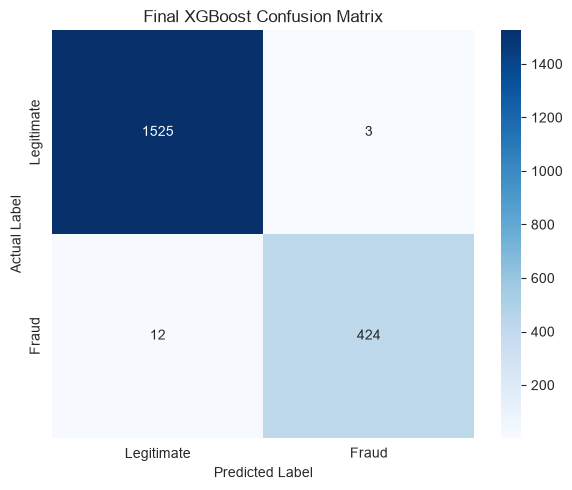

In [56]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    y_test,
    test_pred
)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Final XGBoost Confusion Matrix")

plt.tight_layout()
plt.show()

### 9.5 Classification Report

A detailed classification report is generated to show precision, recall and F1-score for both legitimate and fraudulent accounts.

In [57]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        test_pred,
        target_names=["Legitimate", "Fraud"],
        digits=4
    )
)

              precision    recall  f1-score   support

  Legitimate     0.9922    0.9980    0.9951      1528
       Fraud     0.9930    0.9725    0.9826       436

    accuracy                         0.9924      1964
   macro avg     0.9926    0.9853    0.9889      1964
weighted avg     0.9924    0.9924    0.9923      1964



### 9.6 Cross-Validation vs Final Test Performance

The final test performance is compared with the cross-validated training performance to assess generalization.

The test set was not used during model selection, hyperparameter tuning, or threshold selection.

In [58]:
comparison = pd.DataFrame({
    "Metric": [
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
        "PR-AUC"
    ],
    "OOF / CV": [
        xgb_best_row["precision"],
        xgb_best_row["recall"],
        xgb_best_row["f1"],
        np.nan,
        xgb_search.best_score_
    ],
    "Final Test": [
        final_precision,
        final_recall,
        final_f1,
        final_roc_auc,
        final_pr_auc
    ]
})

display(
    comparison.round(4)
)

,Metric,OOF / CV,Final Test
0,Precision,0.9936,0.9930
1,Recall,0.9799,0.9725
2,F1-score,0.9867,0.9826
3,ROC-AUC,NaN,0.9993
4,PR-AUC,0.9987,0.9980


### 9.7 Final Evaluation Summary

The tuned XGBoost model was selected for final evaluation based on training-only cross-validation and hyperparameter tuning. It achieved a tuned cross-validated PR-AUC of **0.9987**.

An operating probability threshold of **0.60** was selected using out-of-fold training predictions without using the test set.

The selected XGBoost pipeline was then retrained on the complete training dataset and evaluated on the previously untouched test set containing **1,964 accounts**, including **436 fraudulent accounts**.

The final test results were:

- **Accuracy:** 0.9924
- **Precision:** 0.9930
- **Recall:** 0.9725
- **F1-score:** 0.9826
- **ROC-AUC:** 0.9993
- **PR-AUC:** 0.9980

The confusion matrix contained:

- **True Negatives (TN):** 1,525
- **False Positives (FP):** 3
- **False Negatives (FN):** 12
- **True Positives (TP):** 424

The model correctly identified **424 of the 436 fraudulent accounts**, corresponding to a fraud recall of **97.25%**. Only **3 legitimate accounts** were incorrectly classified as fraudulent.

The small decrease from the training-based OOF PR-AUC (**0.9987**) to the final test PR-AUC (**0.9980**) indicates that the model maintained very strong performance on previously unseen accounts.

The test set was used only for the final evaluation and was not used for model selection, hyperparameter tuning, or threshold selection.

## 10. Model Interpretation / SHAP

SHAP (SHapley Additive exPlanations) is used to interpret the final XGBoost model.

The analysis identifies which transaction-behaviour features have the greatest influence on fraud predictions and shows whether higher or lower feature values tend to increase or decrease the model's predicted fraud probability.

SHAP interpretation is performed after final model selection and does not change the trained model or its final test performance.

### 10.1 Prepare Data for SHAP

In [59]:
import shap

# Extract preprocessing and XGBoost components
final_imputer = final_model.named_steps["imputer"]
final_xgb = final_model.named_steps["model"]

# Transform the test data using the fitted imputer
X_test_imputed = final_imputer.transform(X_test)

# Convert back to DataFrame so feature names are preserved
X_test_imputed = pd.DataFrame(
    X_test_imputed,
    columns=X_test.columns,
    index=X_test.index
)

print("SHAP input shape:", X_test_imputed.shape)
print("Feature count:", len(X_test_imputed.columns))

SHAP input shape: (1964, 50)
Feature count: 50


### 10.2 Create SHAP Explainer

A TreeExplainer is used because the final model is XGBoost. A representative subset of the test data is used for visualization to keep the SHAP analysis computationally efficient while preserving the previously untouched test results.

In [60]:
# Use a fixed subset for SHAP visualization
SHAP_SAMPLE = min(1000, len(X_test_imputed))

X_shap = X_test_imputed.sample(
    n=SHAP_SAMPLE,
    random_state=42
)

print("SHAP sample size:", len(X_shap))

# Create TreeSHAP explainer
explainer = shap.TreeExplainer(final_xgb)

print("SHAP explainer created.")

SHAP sample size: 1000
SHAP explainer created.


In [61]:
print("Calculating SHAP values...")

shap_values = explainer.shap_values(X_shap)

print("SHAP calculation completed.")

print("SHAP shape:", shap_values.shape)
print("Input shape:", X_shap.shape)

Calculating SHAP values...
SHAP calculation completed.
SHAP shape: (1000, 50)
Input shape: (1000, 50)


### 10.3 SHAP Feature Importance Summary

The SHAP summary plot ranks features according to their overall contribution to the model's predictions.

Features near the top have a greater influence on the model. Positive SHAP values indicate that a feature pushes the prediction toward the fraudulent class, while negative SHAP values push the prediction toward the legitimate class.

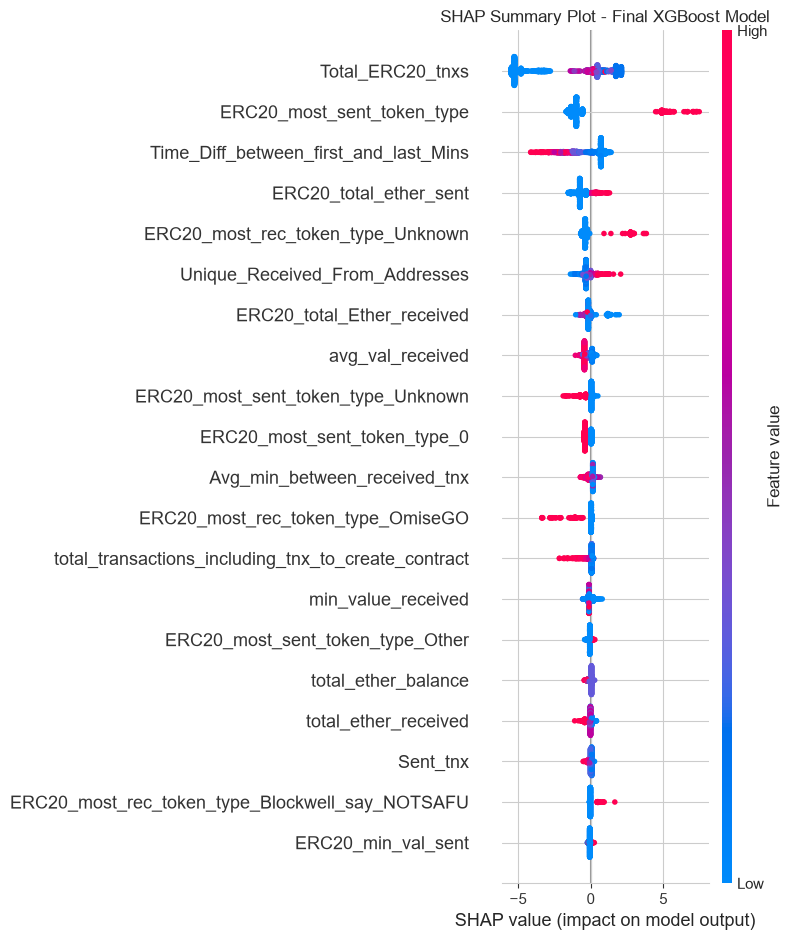

In [62]:
plt.figure(figsize=(10, 8))

shap.summary_plot(
    shap_values,
    X_shap,
    show=False,
    max_display=20
)

plt.title(
    "SHAP Summary Plot - Final XGBoost Model"
)

plt.tight_layout()
plt.show()

### 10.4 Global SHAP Feature Importance

Mean absolute SHAP values are used to rank the features according to their overall influence on the final XGBoost model.

In [63]:
# Calculate mean absolute SHAP importance
shap_importance = pd.DataFrame({
    "Feature": X_shap.columns,
    "Mean |SHAP|": np.abs(shap_values).mean(axis=0)
})

shap_importance = (
    shap_importance
    .sort_values("Mean |SHAP|", ascending=False)
    .reset_index(drop=True)
)

print("Top 20 features by mean absolute SHAP value:")

display(
    shap_importance.head(20).round(4)
)

Top 20 features by mean absolute SHAP value:


,Feature,Mean |SHAP|
0,Total_ERC20_tnxs,2.7643
1,ERC20_most_sent_token_type,1.5883
2,Time_Diff_between_first_and_last_Mins,1.0613
3,ERC20_total_ether_sent,0.6819
4,ERC20_most_rec_token_type_Unknown,0.5631
5,Unique_Received_From_Addresses,0.3206
6,ERC20_total_Ether_received,0.2515
7,avg_val_received,0.2301
8,ERC20_most_sent_token_type_Unknown,0.2298
9,ERC20_most_sent_token_type_0,0.2109


### 10.5 SHAP Global Importance Plot

A bar plot of mean absolute SHAP values provides a compact ranking of the most influential transaction-behaviour features.

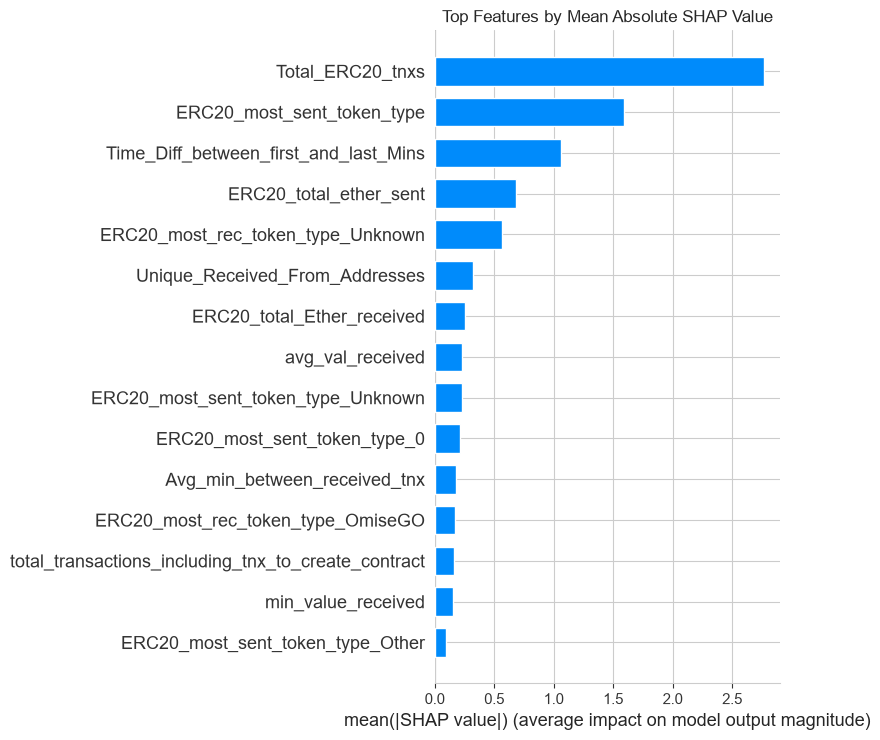

In [64]:
plt.figure(figsize=(10, 7))

shap.summary_plot(
    shap_values,
    X_shap,
    plot_type="bar",
    show=False,
    max_display=15
)

plt.title(
    "Top Features by Mean Absolute SHAP Value"
)

plt.tight_layout()
plt.show()

In [65]:
top_features = shap_importance.head(10).copy()

print("Top 10 features influencing fraud prediction:")

display(
    top_features.round(4)
)

Top 10 features influencing fraud prediction:


,Feature,Mean |SHAP|
0,Total_ERC20_tnxs,2.7643
1,ERC20_most_sent_token_type,1.5883
2,Time_Diff_between_first_and_last_Mins,1.0613
3,ERC20_total_ether_sent,0.6819
4,ERC20_most_rec_token_type_Unknown,0.5631
5,Unique_Received_From_Addresses,0.3206
6,ERC20_total_Ether_received,0.2515
7,avg_val_received,0.2301
8,ERC20_most_sent_token_type_Unknown,0.2298
9,ERC20_most_sent_token_type_0,0.2109


### 10.6 Direction of Feature Influence

For the most important features, the relationship between feature values and SHAP values is examined to determine whether higher or lower feature values tend to push the model prediction toward the fraudulent class.

Positive SHAP values indicate greater contribution toward the fraud class, while negative SHAP values indicate contribution toward the legitimate class.

In [66]:
# Calculate directional SHAP summary for the top 10 features

top10_features = shap_importance.head(10)["Feature"].tolist()

direction_rows = []

for feature in top10_features:

    feature_idx = X_shap.columns.get_loc(feature)

    feature_values = X_shap[feature].values
    feature_shap = shap_values[:, feature_idx]

    # Correlation between feature value and SHAP contribution
    corr = np.corrcoef(
        feature_values,
        feature_shap
    )[0, 1]

    direction_rows.append({
        "Feature": feature,
        "Mean |SHAP|": np.abs(feature_shap).mean(),
        "SHAP correlation": corr
    })

direction_df = pd.DataFrame(direction_rows)

display(
    direction_df.round(4)
)

,Feature,Mean |SHAP|,SHAP correlation
0,Total_ERC20_tnxs,2.7643,0.5565
1,ERC20_most_sent_token_type,1.5883,0.9878
2,Time_Diff_between_first_and_last_Mins,1.0613,-0.9064
3,ERC20_total_ether_sent,0.6819,0.7713
4,ERC20_most_rec_token_type_Unknown,0.5631,0.9852
5,Unique_Received_From_Addresses,0.3206,0.7737
6,ERC20_total_Ether_received,0.2515,-0.2856
7,avg_val_received,0.2301,-0.8550
8,ERC20_most_sent_token_type_Unknown,0.2298,-0.9125
9,ERC20_most_sent_token_type_0,0.2109,-0.9915


### 10.7 SHAP Interpretation Summary
The SHAP analysis was used to interpret the final XGBoost fraud-detection model. The most influential feature was **Total_ERC20_tnxs**, with a mean absolute SHAP value of **2.7643**, followed by **ERC20_most_sent_token_type** (**1.5883**) and **Time_Diff_between_first_and_last_Mins** (**1.0613**).

The results indicate that ERC20 transaction activity is particularly influential in the model's fraud predictions. Other important behavioural signals include the time span of account activity, total Ether transferred through ERC20 transactions, the number of unique addresses from which Ether was received, and the average value of received transactions.

The directional analysis suggests that higher values of **Total_ERC20_tnxs**, **ERC20_total_ether_sent**, and **Unique_Received_From_Addresses** generally correspond to greater model contribution toward the fraudulent class. In contrast, higher values of **Time_Diff_between_first_and_last_Mins** and **avg_val_received** generally correspond to lower fraud contribution.

The categorical token-type features also have substantial influence on the model. Because these variables were one-hot encoded, their SHAP values represent the contribution of specific token-category indicators rather than a numerical increase in token type.

These results describe associations learned by the machine-learning model and should not be interpreted as causal relationships.



## 11. New Account Prediction System

This section uses the trained XGBoost model to predict whether new Ethereum accounts are likely to be fraudulent or legitimate.

The prediction system accepts an external CSV file containing the original 40 account-level transaction features. It applies the same preprocessing steps used during model development, generates fraud probabilities, applies the selected classification threshold of 0.60, and exports the results.

**Input:** CSV file containing new Ethereum account features.

**Output:** Fraud probability, predicted class, and a downloadable CSV results file.

**Important:** The input CSV must not contain the target column `FLAG`.



### 11.1 Prediction Workflow

The new-account prediction process follows these steps:

1. Select an external CSV file.
2. Validate the required input features.
3. Handle unknown categorical values.
4. Apply the training-derived categorical encoding.
5. Apply signed-log transformation.
6. Remove correlated features and apply training-derived outlier limits.
7. Align the processed features with the trained model.
8. Generate fraud probabilities using XGBoost.
9. Classify each account using the threshold of 0.60.
10. Save the prediction results to a new CSV file.

The model and preprocessing parameters are reused from the earlier training sections. No retraining is performed here.



### 11.2 Input Data Requirements

Each row in the input CSV represents one Ethereum account.

The CSV must contain the same 40 predictor columns used to train the model.

- Do not include `FLAG`, because the actual class is unknown for new accounts.
- Keep the original column names.
- Do not manually encode categorical token types.
- Do not apply log transformations or outlier capping to the CSV yourself. The prediction system handles these steps.
- Use account-level transaction features calculated in the same way as the training dataset.

Two synthetic testing files are provided:

- `ethereum_new_accounts_test_1200.csv` — 1,200 rows.
- `ethereum_new_accounts_stress_test_1500.csv` — 1,500 rows.

These files test the prediction workflow; they are not real blockchain observations.


In [95]:

def preprocess_new_accounts(raw_data):
    """
    Prepare new Ethereum account records using the same
    training-derived preprocessing rules used by the model.
    """

    data = raw_data.copy()

    # 1. Validate the original input features
    required_features = X_train_base.columns.tolist()

    missing_features = [
        col for col in required_features
        if col not in data.columns
    ]

    if missing_features:
        raise ValueError(
            "The input CSV is missing required features:\n"
            + str(missing_features)
        )

    # Keep the original feature columns in training order
    data = data[required_features].copy()

    # 2. Handle unknown categorical values
    data = fill_unknown(data)
    data = group_rare(data)

    # 3. Apply one-hot encoding using the training schema
    data_encoded = pd.get_dummies(
        data,
        columns=cat_cols,
        dtype=int
    )

    data_encoded = data_encoded.reindex(
        columns=X_tr_enc.columns,
        fill_value=0
    )

    # 4. Apply the same signed-log transformation
    data_log = data_encoded.copy()
    data_log[skewed] = signed_log(data_log[skewed])

    # 5. Remove features excluded during correlation filtering
    data_corr = data_log.drop(
        columns=drop_corr,
        errors="ignore"
    )

    # 6. Apply outlier limits learned from the training data
    data_cap = data_corr.copy()
    data_cap[cap_cols] = data_corr[cap_cols].clip(
        lower=lo[cap_cols],
        upper=hi[cap_cols],
        axis=1
    )

    # 7. Clean feature names and match the final model schema
    data_final = data_cap.copy()
    data_final.columns = [
        clean_name(col) for col in data_final.columns
    ]

    data_final = data_final.reindex(
        columns=X_train.columns,
        fill_value=0
    )

    return data_final



### 11.3 Fraud Prediction Function

The following function takes preprocessed account records and passes them to the trained XGBoost model.

For every account, it returns:

- `Fraud_Probability`: estimated probability of fraud, from 0 to 1.
- `Prediction`: `Fraud` if the probability is at least 0.60; otherwise `Legitimate`.

The 0.60 threshold is the threshold selected during model evaluation.


In [96]:

def predict_new_accounts(raw_data):
    """
    Predict fraud probabilities and classifications
    for new Ethereum account records.
    """

    # Prepare the input using the existing preprocessing pipeline
    processed_data = preprocess_new_accounts(raw_data)

    # Generate fraud probabilities
    probabilities = final_model.predict_proba(
        processed_data
    )[:, 1]

    # Apply the selected classification threshold
    predictions = (
        probabilities >= final_threshold
    ).astype(int)

    # Create the prediction results
    results = pd.DataFrame({
        "Fraud_Probability": probabilities,
        "Prediction": predictions
    }, index=raw_data.index)

    # Convert numeric predictions to readable labels
    results["Prediction"] = results["Prediction"].map({
        0: "Legitimate",
        1: "Fraud"
    })

    return results



### 11.4 Load New Account Data

This cell loads an external CSV file for prediction.

Choose one of the two provided testing files by changing `csv_filename`. The notebook searches the current directory and the common `data` folder locations.

The CSV is used only for prediction. The model is not trained again, and no actual fraud labels are required.


In [97]:
from pathlib import Path
import pandas as pd

# Select ONE input file
csv_filename = "ethereum_new_accounts_test_1200.csv"
# csv_filename = "ethereum_new_accounts_stress_test_1500.csv"

possible_paths = [
    Path("data") / csv_filename,
    Path("../data") / csv_filename,
    Path(csv_filename)
]

input_path = next((p for p in possible_paths if p.is_file()), None)

if input_path is None:
    raise FileNotFoundError(
        f"Cannot find '{csv_filename}'. "
        "Place the CSV in your project's data folder "
        "or update the file path in this cell."
    )

new_accounts_df = pd.read_csv(input_path)

# Remove accidental spaces around column names
new_accounts_df.columns = new_accounts_df.columns.str.strip()

print("Input file:", input_path)
print("Number of account records:", len(new_accounts_df))
print("Number of input columns:", len(new_accounts_df.columns))

display(new_accounts_df.head())

Input file: ..\data\ethereum_new_accounts_test_1200.csv
Number of account records: 1200
Number of input columns: 40


,Avg min between sent tnx,Avg min between received tnx,Time Diff between first and last (Mins),Sent tnx,Received Tnx,Number of Created Contracts,Unique Received From Addresses,Unique Sent To Addresses,min value received,max value received,...,ERC20 most sent token type,ERC20_most_rec_token_type,ERC20 min val rec,ERC20 max val rec,ERC20 avg val rec,ERC20 min val sent,ERC20 max val sent,ERC20 avg val sent,ERC20 uniq sent addr.1,ERC20 uniq rec contract addr
0,33.209443,309.181599,11967.445676,10,8,1,3,2,0.083327,8.625349,...,StatusNetwork,OMG,0.012083,1.875850,0.025884,0.002265,1.694474,0.014907,1,2
1,1055.785009,419.079787,384.518748,10,11,1,1,5,0.070383,16.502223,...,Unknown,EOS,10.915657,817.017419,16.415557,0.004151,0.295530,0.004312,0,0
2,1033.986433,85.563173,765.660600,7,15,2,2,2,0.227982,64.703183,...,0xTokenC,0xTokenE,0.697144,591.737474,2.840486,0.000182,0.031097,0.000128,0,2
3,12379.031109,19.345461,3158.885881,8,10,2,2,3,0.017653,0.776921,...,Storj,0xTokenB,0.057544,10.177386,0.044039,0.003597,0.194595,0.006553,1,0
4,32.219042,9.437793,49804.304340,11,9,0,1,4,0.441066,28.461135,...,Golem,Storj,0.300143,219.709707,4.149083,0.139811,19.296847,0.298433,0,3



### 11.5 Validate Input Features

Before making predictions, the system checks whether the CSV contains all 40 required predictor columns.

The target column `FLAG` is not allowed in the input. Extra columns are reported and ignored by the preprocessing function, while missing required features cause an error so that invalid predictions are not generated.


In [98]:
import re

# The target must not be included in prediction input
if "FLAG" in new_accounts_df.columns:
    raise ValueError(
        "The input CSV contains 'FLAG'. "
        "Remove this target column before prediction."
    )

# Match CSV column names to training column names
# (ignores case, spaces, and punctuation differences)
def norm(s):
    return re.sub(r"[^a-z0-9]", "", s.lower())

train_lookup = {norm(c): c for c in X_train_base.columns}

new_accounts_df = new_accounts_df.rename(columns={
    c: train_lookup[norm(c)]
    for c in new_accounts_df.columns
    if norm(c) in train_lookup
})

required_features = X_train_base.columns.tolist()
provided_features = new_accounts_df.columns.tolist()

missing_features = [c for c in required_features if c not in provided_features]
extra_features = [c for c in provided_features if c not in required_features]

print("Required feature count:", len(required_features))
print("Provided column count:", len(provided_features))
print("Missing required features:", missing_features)
print("Extra columns that will be ignored:", extra_features)

if missing_features:
    raise ValueError(
        "CSV validation failed. The input file must contain "
        "all required training feature columns. "
        "Check the missing-column list above."
    )

# Use the exact training column order
new_accounts_df = new_accounts_df[required_features]

print("\nCSV validation passed.")

Required feature count: 40
Provided column count: 40
Missing required features: []
Extra columns that will be ignored: []

CSV validation passed.



### 11.6 Generate and Display Predictions

The trained XGBoost model generates fraud probabilities and classifications for all accounts in the input CSV.

The system displays a summary of the predictions, including the total number of accounts analyzed, predicted fraudulent accounts, predicted legitimate accounts, and the fraud prediction rate.

The first 20 account predictions are displayed in a table. All predictions remain available in the `results_df` DataFrame for further analysis. No output CSV file is created.



# Ethereum Fraud Detection Dashboard
### New Account Prediction Results



<div style="display:grid;
            grid-template-columns:repeat(2,minmax(0,1fr));
            gap:12px;
            margin:15px 0;">

  <div style="background:#e8f1ff;padding:18px;border-radius:10px;">
    <div style="color:#334155;font-size:14px;">Total Accounts Analyzed</div>
    <div style="color:#1d4ed8;font-size:28px;font-weight:bold;">
      1,200
    </div>
  </div>

  <div style="background:#fee2e2;padding:18px;border-radius:10px;">
    <div style="color:#7f1d1d;font-size:14px;">Predicted Fraud</div>
    <div style="color:#b91c1c;font-size:28px;font-weight:bold;">
      80
    </div>
  </div>

  <div style="background:#dcfce7;padding:18px;border-radius:10px;">
    <div style="color:#14532d;font-size:14px;">Predicted Legitimate</div>
    <div style="color:#15803d;font-size:28px;font-weight:bold;">
      1,120
    </div>
  </div>

  <div style="background:#f3e8ff;padding:18px;border-radius:10px;">
    <div style="color:#581c87;font-size:14px;">Fraud Prediction Rate</div>
    <div style="color:#7e22ce;font-size:28px;font-weight:bold;">
      6.67%
    </div>
  </div>
</div>


Average predicted fraud probability: 21.72%


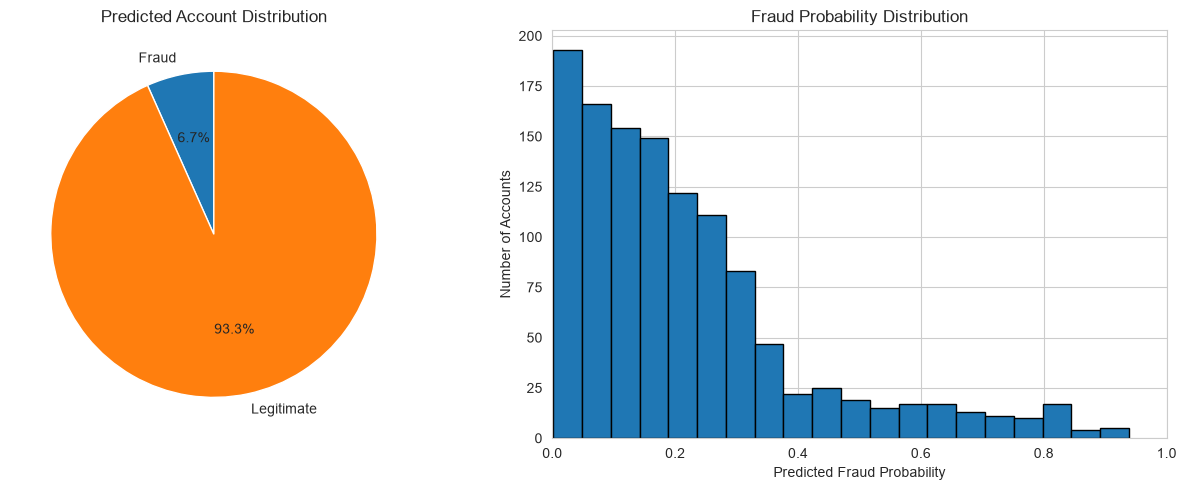

### Account-Level Prediction Results

,Fraud_Probability,Prediction
0,29.36%,Legitimate
1,1.84%,Legitimate
2,12.50%,Legitimate
3,34.72%,Legitimate
4,4.39%,Legitimate
5,17.29%,Legitimate
6,1.51%,Legitimate
7,6.85%,Legitimate
8,5.21%,Legitimate
9,7.56%,Legitimate


Showing first 20 of 1,200 account predictions.
All predictions are available in results_df.


In [99]:

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display, Markdown

# --------------------------------------------------
# 1. GENERATE PREDICTIONS
# --------------------------------------------------

prediction_df = predict_new_accounts(new_accounts_df)

results_df = pd.concat(
    [
        new_accounts_df.reset_index(drop=True),
        prediction_df.reset_index(drop=True)
    ],
    axis=1
)

# --------------------------------------------------
# 2. CALCULATE DASHBOARD METRICS
# --------------------------------------------------

total_accounts = len(results_df)

fraud_count = (
    results_df["Prediction"] == "Fraud"
).sum()

legitimate_count = (
    results_df["Prediction"] == "Legitimate"
).sum()

fraud_percentage = (
    fraud_count / total_accounts * 100
    if total_accounts > 0 else 0
)

mean_fraud_probability = (
    results_df["Fraud_Probability"].mean() * 100
    if total_accounts > 0 else 0
)

# --------------------------------------------------
# 3. DASHBOARD TITLE AND SUMMARY CARDS
# --------------------------------------------------

display(Markdown("""
# Ethereum Fraud Detection Dashboard
### New Account Prediction Results
"""))

# Simple dashboard cards using HTML
dashboard_html = f"""
<div style="display:grid;
            grid-template-columns:repeat(2,minmax(0,1fr));
            gap:12px;
            margin:15px 0;">

  <div style="background:#e8f1ff;padding:18px;border-radius:10px;">
    <div style="color:#334155;font-size:14px;">Total Accounts Analyzed</div>
    <div style="color:#1d4ed8;font-size:28px;font-weight:bold;">
      {total_accounts:,}
    </div>
  </div>

  <div style="background:#fee2e2;padding:18px;border-radius:10px;">
    <div style="color:#7f1d1d;font-size:14px;">Predicted Fraud</div>
    <div style="color:#b91c1c;font-size:28px;font-weight:bold;">
      {fraud_count:,}
    </div>
  </div>

  <div style="background:#dcfce7;padding:18px;border-radius:10px;">
    <div style="color:#14532d;font-size:14px;">Predicted Legitimate</div>
    <div style="color:#15803d;font-size:28px;font-weight:bold;">
      {legitimate_count:,}
    </div>
  </div>

  <div style="background:#f3e8ff;padding:18px;border-radius:10px;">
    <div style="color:#581c87;font-size:14px;">Fraud Prediction Rate</div>
    <div style="color:#7e22ce;font-size:28px;font-weight:bold;">
      {fraud_percentage:.2f}%
    </div>
  </div>
</div>
"""

display(Markdown(dashboard_html))

print(
    f"Average predicted fraud probability: "
    f"{mean_fraud_probability:.2f}%"
)

# --------------------------------------------------
# 4. VISUALIZE PREDICTION DISTRIBUTION
# --------------------------------------------------

if total_accounts > 0:
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Pie chart
    labels = ["Fraud", "Legitimate"]
    values = [fraud_count, legitimate_count]

    axes[0].pie(
        values,
        labels=labels,
        autopct="%1.1f%%",
        startangle=90
    )

    axes[0].set_title("Predicted Account Distribution")

    # Probability histogram
    axes[1].hist(
        results_df["Fraud_Probability"],
        bins=20,
        edgecolor="black"
    )

    axes[1].set_title("Fraud Probability Distribution")
    axes[1].set_xlabel("Predicted Fraud Probability")
    axes[1].set_ylabel("Number of Accounts")
    axes[1].set_xlim(0, 1)

    plt.tight_layout()
    plt.show()

# --------------------------------------------------
# 5. DISPLAY ACCOUNT-LEVEL RESULTS
# --------------------------------------------------

# Display account-level prediction results without pandas styling
display(Markdown("### Account-Level Prediction Results"))

display_df = results_df[
    ["Fraud_Probability", "Prediction"]
].head(20).copy()

# Format probabilities as percentages
display_df["Fraud_Probability"] = (
    display_df["Fraud_Probability"].map(
        lambda value: f"{value:.2%}"
    )
)

display(display_df)

print(
    f"Showing first {min(20, len(results_df))} "
    f"of {len(results_df):,} account predictions."
)

print("All predictions are available in results_df.")




### 11.7 New Account Prediction Summary

The new-account prediction system applies the trained XGBoost model to an external CSV dataset without retraining.

The system validates the input features, applies the established preprocessing pipeline, generates fraud probabilities, and classifies accounts using the selected threshold of 0.60.

The prediction summary and account-level results are displayed directly in the notebook. The complete results are retained in the `results_df` DataFrame for further analysis.

**Limitation:** The supplied testing datasets contain synthetic records. Their predictions demonstrate that the pipeline runs, but do not establish real-world fraud detection accuracy.
